In [1]:
from langgraph.graph import StateGraph, START,END 
from typing import TypedDict,Annotated
# from langchain_openai import ChatOpenAI
from pydantic import BaseModel, Field
from dotenv import load_dotenv
import os
import operator

load_dotenv()
api_key = os.getenv("GROQ_API_KEY")
model_name = os.getenv("MODEL_NAME")

In [2]:
from  langchain_groq import ChatGroq
model=ChatGroq(
    api_key=api_key,
    model_name=model_name,
    temperature=0.0)

In [3]:
class QuadState(TypedDict):
    num1 : int
    num2 : int
    num3 : int

    equation : str 
    discriminant : float
    result : str


In [ ]:
def show_equation(state: QuadState):
    equation = f"{state['num1']}x2{state['num2']}x{state['num3']}"

    return {'equation':equation}

def calculate_discriminant(state : QuadState):
    discriminant=state['num2']**2 - (4*state['num1']*state['num3'])
    return {'discriminant':discriminant}

def real_roots(state : QuadState):
    root1 = (-state['num2'] + (state['discriminant']**0.5)) / (2*state['num1'])
    root2 = (-state['num2'] - (state['discriminant']**0.5)) / (2*state['num1'])
    result = f"The equation has two real roots: {root1} and {root2}"
    return {'result':result}


def repeated_roots(state : QuadState):
    root = (-state['num2']) / (2*state['num1'])
    result = f"Only repeating roots: {root}"
    return {'result':result}


def no_real_roots(state : QuadState):
    return {'result': "The equation has no real roots."}

def check_condition(state : QuadState):
    if state['discriminant'] > 0:
        return {'next_node':'real_roots'}
    elif state['discriminant'] == 0:
        return {'next_node':'repeated_roots'}
    else:
        return {'next_node':'no_real_roots'} 

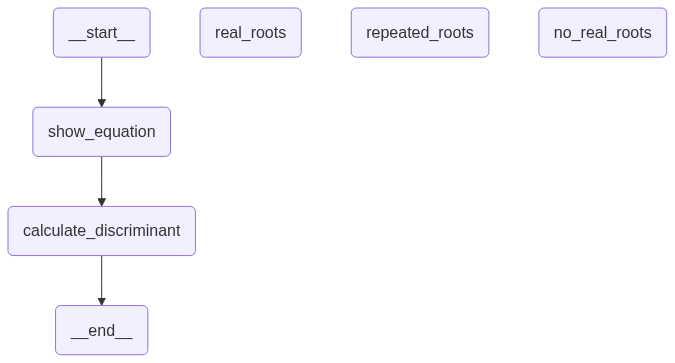

In [14]:
graph= StateGraph(QuadState)

graph.add_node("show_equation",show_equation)
graph.add_node("calculate_discriminant",calculate_discriminant)
graph.add_node("real_roots",real_roots)
graph.add_node("repeated_roots",repeated_roots)
graph.add_node("no_real_roots",no_real_roots)



graph.add_edge(START, 'show_equation')
graph.add_edge('show_equation','calculate_discriminant')
graph.add_conditional_edges("calculate_discriminant",check_condition)
graph.add_edge('real_roots',END)
graph.add_edge('repeated_roots',END)
graph.add_edge('no_real_roots',END)


graph.compile()

In [15]:
init_state= {
    "num1":4,
    "num2":-5,
    "num3":-4,
}
workflow.invoke(init_state)

Task calculate_discriminant with path ('__pregel_pull', 'calculate_discriminant') wrote to unknown channel branch:to:{'next_node': 'real_roots'}, ignoring it.


{'num1': 4,
 'num2': -5,
 'num3': -4,
 'equation': '4 x 2 -5 x -4',
 'discriminant': 89}